In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})
c = Table.read(RES / "colour_catalogue.ecsv")
model = Table.read(RES / "star_count_model.ecsv")
sdss = Table.read(DATA / "sdss_stars.csv", format="ascii.csv", comment="#")

BINS = [(20, 22), (22, 23), (23, 24), (24, 25)]
PAPER_COMPLETENESS = {(20, 22): 99, (22, 23): 100, (23, 24): 97, (24, 25): 85}
MODEL_LINES = [(0.5, "models: main peak", "--"), (0.9, "q0=0.05 model: 2nd peak", "-."),
               (1.5, "q0=0.05 model: E/S0 spike", ":"), (1.7, "models: red end", (0, (1, 3)))]
TABLE13_Z0 = {"E/S0": 0.70, "Sab": 0.70, "Sbc": 0.59, "Scd": 0.53, "Sdm": 0.47}
EDGES = np.arange(-1.0, 3.0001, 0.1)
SYS_ERR = 0.05                      # systematic colour uncertainty for galaxies (notebook 8)

nonstar = c["class"] != "star"
r_clean = (c["flag_r"] == 0) & np.isfinite(c["r_gal"])
has_colour = r_clean & (c["flag_i"] == 0) & c["i_detected"] & np.isfinite(c["r_minus_i"])
samples = {"A": nonstar & (c["class"] == "galaxy"), "B": nonstar}

In [2]:
rng = np.random.default_rng(1)
rs, ri_all = np.asarray(sdss["psfMag_r"]), np.asarray(sdss["psfMag_r"] - sdss["psfMag_i"])
good_star = (sdss["clean"] == 1) & (sdss["psfMagErr_i"] < 0.2)
STAR_R, STAR_RI, STAR_W = [], [], []
for lo, nm, ns, ncl in zip(model["mag_lo"], model["n_star_model"], model["n_star_sdss"], model["n_star_classified"]):
    expected = ns if lo + 0.5 <= 21.5 else (nm if np.isfinite(nm) else 0.0)
    left = max(expected - ncl, 0.0)
    if left <= 0 or lo + 0.5 > 25.5:
        continue
    c_lo, c_hi = (lo - 0.75, lo + 1.25) if lo < 22 else (21.0, 22.5)
    pool = ri_all[good_star & (rs > c_lo) & (rs < c_hi)]
    if len(pool):
        STAR_R.append(rng.uniform(lo, lo + 0.5, 200)); STAR_RI.append(rng.choice(pool, 200)); STAR_W.append(np.full(200, left / 200))
STAR_R, STAR_RI, STAR_W = map(np.concatenate, (STAR_R, STAR_RI, STAR_W))

In [3]:
def stats(x):
    x = x[np.isfinite(x)]
    if not len(x):
        return {}
    h, e = np.histogram(x, EDGES)
    return {"n": len(x), "median": float(np.median(x)), "mode": float(e[np.argmax(h)] + 0.05)}


def histograms(system, title, fname):
    paper = system == "paper"
    mag_col, col_col = ("R_cousins", "R_I_cousins") if paper else ("r_gal", "r_minus_i")
    smag = STAR_R - 0.2936 * STAR_RI - 0.1439 if paper else STAR_R
    scol = 0.9508 * STAR_RI + 0.2381 if paper else STAR_RI
    xlabel = "R - I colour (Kron-Cousins)" if paper else "r - i colour (SDSS AB)"
    lab = "R" if paper else "r"
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    rows = []
    for k, (ax, (lo, hi)) in enumerate(zip(axes.ravel(), BINS)):
        inbin = r_clean & (c[mag_col] >= lo) & (c[mag_col] < hi)
        nB = int((inbin & samples["B"]).sum()); xB = np.asarray(c[col_col][inbin & samples["B"] & has_colour])
        compl = 100 * len(xB) / nB if nB else np.nan
        hB, _ = np.histogram(xB, EDGES)
        sb = (smag >= lo) & (smag < hi)
        hS, _ = np.histogram(scol[sb], EDGES, weights=STAR_W[sb] * compl / 100)
        gal = hB - hS
        xA = np.asarray(c[col_col][inbin & samples["A"] & has_colour])
        ax.step(EDGES[:-1], hB, where="post", color="0.6", lw=1.0, label="all non-stellar sources")
        ax.step(EDGES[:-1], hS, where="post", color="C2", ls=":", lw=1.5, label="expected unclassified stars")
        ax.step(EDGES[:-1], gal, where="post", color="k", lw=2.0, label="galaxies (stars subtracted)")
        if len(xA):
            ax.hist(xA, EDGES, histtype="step", color="C3", lw=1.6, label="classified galaxies only")
        if paper:
            for v, txt, ls in MODEL_LINES:
                ax.axvline(v, color="C0", ls=ls, lw=1, label=txt)
            ax.plot(list(TABLE13_Z0.values()), [0] * 5, "^", color="C1", ms=7, clip_on=False, label="Table 13: z = 0 colours")
        pos = np.clip(gal, 0, None); cum = np.cumsum(pos) / max(pos.sum(), 1)
        med_gal = float(np.interp(0.5, cum, EDGES[1:])); mode_gal = float(EDGES[np.argmax(pos)] + 0.05)
        red = float(pos[EDGES[:-1] >= 1.2].sum() / max(pos.sum(), 1))
        txt = f"{lo} < {lab} < {hi}\ngalaxies: {gal.sum():.0f}\ncolour completeness: {compl:.0f}%"
        if paper:
            txt += f"  (paper: {PAPER_COMPLETENESS[(lo, hi)]}%)"
        if (lo, hi) == (24, 25):
            txt += "\nINCOMPLETE - do not interpret"
        ax.text(0.98, 0.97, txt, transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec="0.8"))
        ax.set_xlim(-1, 3); ax.set_ylim(bottom=0)
        ax.set_xlabel(xlabel); ax.set_ylabel("Number of objects per 0.1 mag")
        if k == 0:
            ax.legend(fontsize=7.5, loc="center right", bbox_to_anchor=(1.0, 0.42))
        rows.append({"bin": f"{lo}-{hi}", "galaxies": round(float(gal.sum())), "classified_galaxies": len(xA),
                     "colour_completeness_%": round(compl), "median": round(med_gal, 2), "mode": round(mode_gal, 2),
                     "red_fraction_gt_1.2": round(red, 3), "expected_stars": round(float(hS.sum()))})
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(FIG / fname); plt.show()
    return Table(rows=rows)

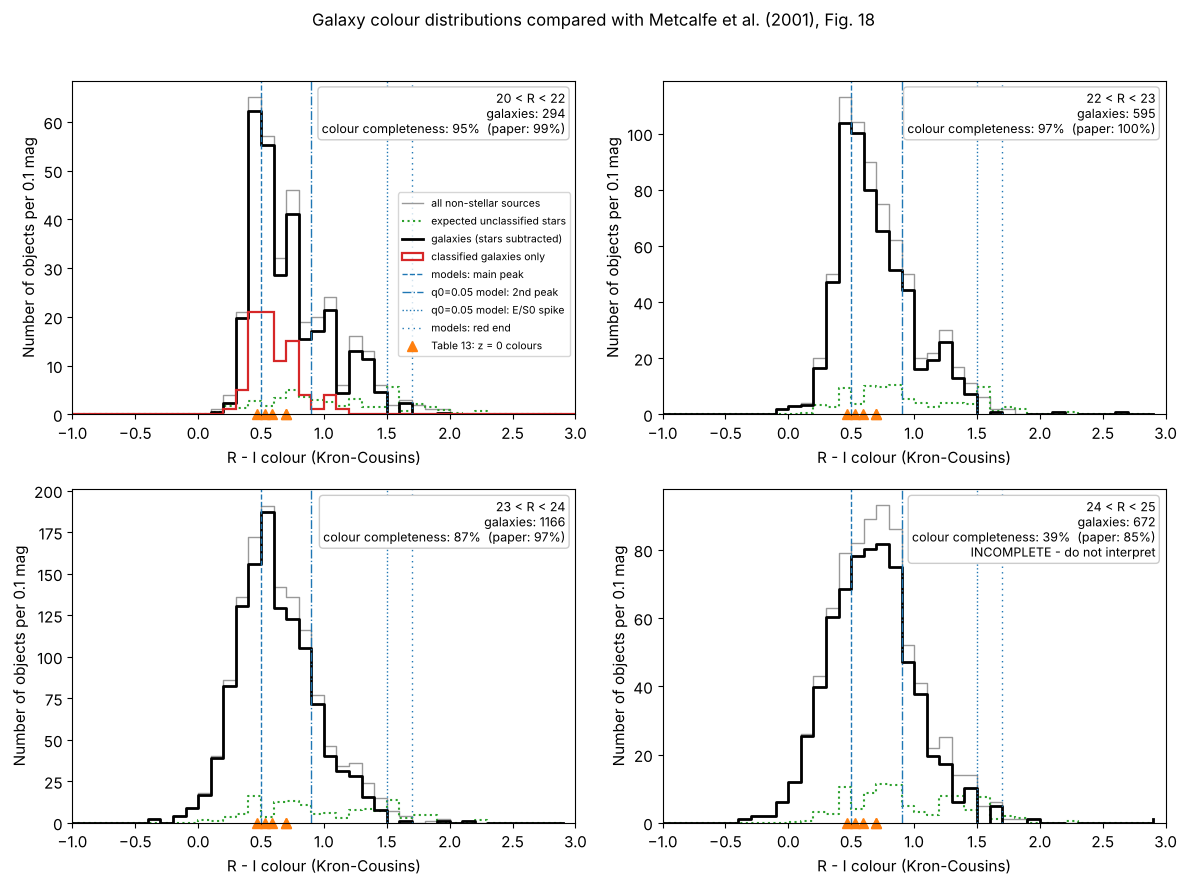

 bin  galaxies classified_galaxies colour_completeness_% median mode red_fraction_gt_1.2 expected_stars
----- -------- ------------------- --------------------- ------ ---- ------------------- --------------
20-22      294                  84                    95   0.63 0.45               0.062             45
22-23      595                   0                    97   0.63 0.45               0.038             90
23-24     1166                   0                    87   0.58 0.55               0.023            133
24-25      672                   0                    39   0.65 0.75               0.034             95


In [4]:
t_paper = histograms("paper", "Galaxy colour distributions compared with Metcalfe et al. (2001), Fig. 18",
                     "09_colour_histograms_vs_paper.png")
t_paper.pprint(max_width=-1)

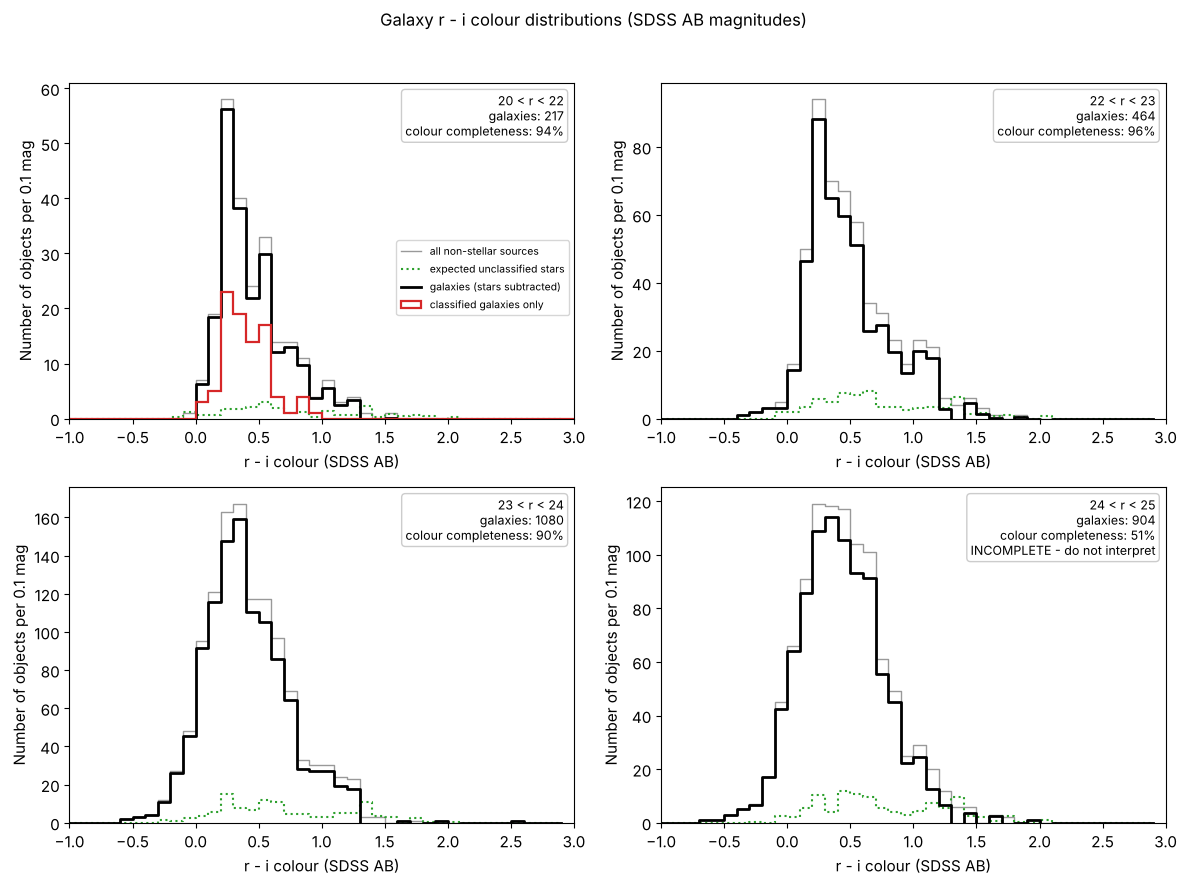

 bin  galaxies classified_galaxies colour_completeness_% median mode red_fraction_gt_1.2 expected_stars
----- -------- ------------------- --------------------- ------ ---- ------------------- --------------
20-22      217                  91                    94   0.38 0.25               0.001             24
22-23      464                   0                    96   0.42 0.25               0.015             71
23-24     1080                   0                    90   0.36 0.35               0.003            112
24-25      904                   0                    51   0.41 0.35               0.008            105


In [5]:
t_sdss = histograms("sdss", "Galaxy r - i colour distributions (SDSS AB magnitudes)", "09_colour_histograms_sdss.png")
t_sdss.pprint(max_width=-1)
json.dump({"paper_system": [dict(r) for r in t_paper], "sdss_ab": [dict(r) for r in t_sdss], "systematic_colour_error": SYS_ERR},
          open(RES / "histogram_summary.json", "w"), indent=1, default=float)

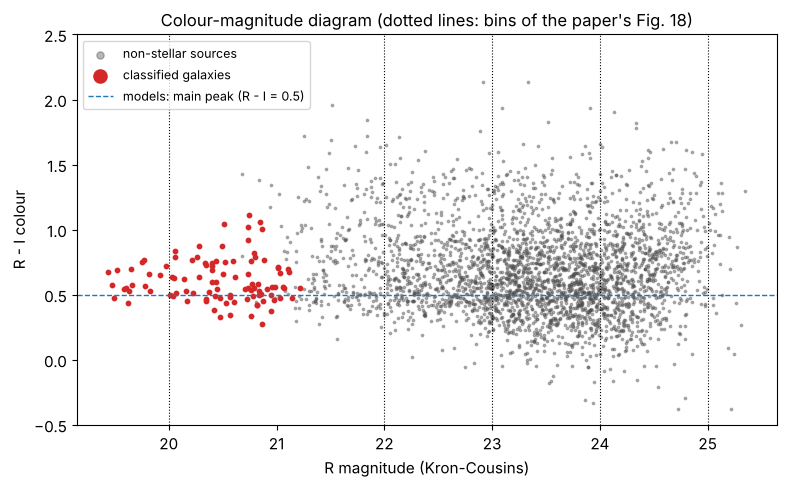

In [6]:
sel = has_colour & nonstar & (c["R_cousins"] > 18) & (c["R_cousins"] < 25.5)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(c["R_cousins"][sel], c["R_I_cousins"][sel], s=3, alpha=0.4, color="0.3", label="non-stellar sources", rasterized=True)
g = has_colour & (c["class"] == "galaxy")
ax.scatter(c["R_cousins"][g], c["R_I_cousins"][g], s=10, color="C3", label="classified galaxies")
for e in (20, 22, 23, 24, 25):
    ax.axvline(e, color="k", ls=":", lw=0.8)
ax.axhline(0.5, color="C0", ls="--", lw=1, label="models: main peak (R - I = 0.5)")
ax.set_ylim(-0.5, 2.5); ax.set_xlabel("R magnitude (Kron-Cousins)"); ax.set_ylabel("R - I colour")
ax.set_title("Colour-magnitude diagram (dotted lines: bins of the paper's Fig. 18)")
ax.legend(markerscale=3, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "09_colour_magnitude.png"); plt.show()